# Proyek Analisis Data: Air Quality Dataset (Beijing Multi-Site 2013–2017)
- **Nama:** Bayu Adji Ramadhan
- **Email:** bayuadji500@gmail.com
- **ID Dicoding:** serpent

## Menentukan Pertanyaan Bisnis

- **Pertanyaan 1:** Stasiun manakah di masing-masing kategori wilayah (*Urban*, *Suburban*, dan *Non-Urban*) yang mencatatkan rata-rata konsentrasi PM2.5 tertinggi dan terendah selama periode tahun 2015 hingga 2017 untuk menentukan prioritas lokasi intervensi pengendalian emisi?
- **Pertanyaan 2:** Pada jam berapakah puncak rata-rata konsentrasi PM2.5 harian terjadi di wilayah *Urban*, *Suburban*, dan *Non-Urban* selama periode tahun 2015 hingga 2017, serta bagaimana pola fluktuasi musimannya pada rentang 2015 hingga 2017 guna mendukung penyusunan jadwal pembatasan operasional kendaraan berat dan peringatan dini kesehatan?

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import glob
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan tabel dan grafik
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

#### Memuat dan Menggabungkan Dataset 12 Stasiun Pemantauan

In [2]:
# Ekstraksi opsional jika arsip zip tersedia dan file CSV belum diekstrak
existing_csv = (
    glob.glob('data/PRSA_Data_*.csv')
    + glob.glob('air_quality_data/**/PRSA_Data_*.csv', recursive=True)
    + glob.glob('PRSA_Data_*.csv')
)

if len(existing_csv) == 0:
    zip_candidates = ['Air-quality-dataset.zip', 'data/Air-quality-dataset.zip']
    zip_path = next((p for p in zip_candidates if os.path.exists(p)), None)
    if zip_path:
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall('air_quality_data')
        print(f"Ekstraksi selesai dari {zip_path}!")

# Mencari seluruh 12 file CSV stasiun pemantauan
for pattern in [
    'data/PRSA_Data_*.csv',
    'air_quality_data/**/PRSA_Data_*.csv',
    'PRSA_Data_*.csv'
]:
    found = sorted(glob.glob(pattern, recursive=True))
    if len(found) == 12:
        csv_files = found
        break

print(f"Total file terdeteksi: {len(csv_files)}")

df_list = [pd.read_csv(file) for file in csv_files]
df = pd.concat(df_list, ignore_index=True)

# Mengecek ukuran total baris dan kolom serta daftar stasiun unik
print(f"Total dimensi data: {df.shape}")
print(f"Jumlah stasiun unik: {df['station'].nunique()}")
print(f"Daftar stasiun: {df['station'].unique()}")

display(df.head())

Total file terdeteksi: 12


Total dimensi data: (420768, 18)
Jumlah stasiun unik: 12
Daftar stasiun: ['Aotizhongxin' 'Changping' 'Dingling' 'Dongsi' 'Guanyuan' 'Gucheng'
 'Huairou' 'Nongzhanguan' 'Shunyi' 'Tiantan' 'Wanliu' 'Wanshouxigong']


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


**Insight:**
- Data hasil penggabungan dari 12 berkas CSV stasiun pemantauan di Beijing menghasilkan satu kesatuan tabel berukuran **420.768 baris dan 18 kolom**, di mana masing-masing stasiun memiliki tepat **35.064 baris** observasi per jam dari **1 Maret 2013 pukul 00:00 hingga 28 Februari 2017 pukul 23:00**.
- Dataset memuat **6 variabel polutan udara utama** (`PM2.5`, `PM10`, `SO2`, `NO2`, `CO`, `O3`), **6 variabel parameter meteorologi** (`TEMP`, `PRES`, `DEWP`, `RAIN`, arah angin `wd`, dan kecepatan angin `WSPM`), serta penanda waktu (`year`, `month`, `day`, `hour`) dan nama stasiun (`station`).
- Ke-12 stasiun pemantauan mencakup tiga karakteristik tata ruang yang berbeda, yakni kawasan pusat perkotaan (*Urban*: `Dongsi`, `Guanyuan`, `Wanshouxigong`, `Tiantan`, `Nongzhanguan`, `Wanliu`, `Aotizhongxin`, `Gucheng`), kawasan penyangga (*Suburban*: `Changping`, `Shunyi`), serta kawasan pinggiran/pegunungan (*Non-Urban*: `Dingling`, `Huairou`).

### Assessing Data

#### Mengidentifikasi Masalah Kualitas Data (Tipe Data, Missing Values, Duplikasi, dan Outliers)

In [3]:
# 1. Memeriksa tipe data dan ringkasan non-null tiap kolom
df.info()

# 2. Memeriksa ringkasan statistik deskriptif (termasuk kolom kategori)
display(df.describe(include="all"))

# 3. Memeriksa jumlah missing values di setiap kolom
print("\nJumlah Missing Values per Kolom:")
display(df.isna().sum())

# 4. Memeriksa jumlah data duplikat
print(f"\nJumlah baris duplikat: {df.duplicated().sum()}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
count,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,412029.000000,414319.000000,411747.000000,408652.000000,400067.000000,407491.000000,420370.000000,420375.000000,420365.000000,420378.000000,418946,420450.000000,420768
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16,NaN,12
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NE,NaN,Aotizhongxin
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,43335,NaN,35064
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,79.793428,104.602618,15.830835,50.638586,1230.766454,57.372271,13.538976,1010.746982,2.490822,0.064476,NaN,1.729711,NaN
std,10122.116943,1.177198,3.448707,8.800102,6.922195,80.822391,91.772426,21.650603,35.127912,1160.182716,56.661607,11.436139,10.474055,13.793847,0.821004,NaN,1.246386,NaN
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.400000,-43.400000,0.000000,NaN,0.000000,NaN
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,20.000000,36.000000,3.000000,23.000000,500.000000,11.000000,3.100000,1002.300000,-8.900000,0.000000,NaN,0.900000,NaN
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,55.000000,82.000000,7.000000,43.000000,900.000000,45.000000,14.500000,1010.400000,3.100000,0.000000,NaN,1.400000,NaN
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,111.000000,145.000000,20.000000,71.000000,1500.000000,82.000000,23.300000,1019.000000,15.100000,0.000000,NaN,2.200000,NaN



Jumlah Missing Values per Kolom:


No             0
year           0
month          0
day            0
hour           0
PM2.5       8739
PM10        6449
SO2         9021
NO2        12116
CO         20701
O3         13277
TEMP         398
PRES         393
DEWP         403
RAIN         390
wd          1822
WSPM         318
station        0
dtype: int64


Jumlah baris duplikat: 0


**Steps to Take:**
- Pada *missing value* dalam nilai polutan dan cuaca, dikarenakan datanya dicatat per jam maka datanya saling bersinambungan secara berurutan waktu (*time series*). Oleh karena itu, penanganan nilai yang hilang dilakukan dengan **interpolasi linier** (mengambil titik tengah antara data 1 jam sebelum dan 1 jam sesudahnya) yang dikelompokkan per stasiun (`groupby('station')`). Untuk sisa *missing value* di ujung awal data dan kolom arah angin (`wd`), akan dituntaskan menggunakan kombinasi `ffill` dan `bfill`.
- Untuk *outliers* tersendiri akan disesuaikan dengan stasiunnya masing-masing (`groupby('station')`) menggunakan batas IQR (*Interquartile Range*) dengan metode *capping* (`clip`) agar jumlah baris *time-series* tetap utuh namun nilai rata-rata (`mean`) dari setiap stasiun tidak terdistorsi oleh lonjakan ekstrem sesaat.

**Insight:**
- Data yang diolah sudah bersih dari duplikasi karena output dari `duplicated().sum()` menghasilkan nilai **0**.
- Berdasarkan ringkasan statistik `describe()`, nilai minimum (`min`) seluruh variabel masih normal karena nilai negatif hanya terdapat pada suhu (`TEMP` hingga `-19,9 °C`) dan titik embun (`DEWP` hingga `-43,4 °C`). Namun, terdapat sejumlah nilai polutan (dari `PM2.5` hingga `O3`) yang melonjak jauh di atas kuartil ketiga (`Q3`), bahkan lebih dari 3 hingga 10 kali lipat (misalnya `PM2.5` mencapai `999 µg/m³` sementara `Q3` berada di `111 µg/m³`), sehingga teridentifikasi sebagai *outliers*. Pada variabel `RAIN`, nilai dari `min` hingga `Q3` adalah `0` (karena mayoritas jam tidak turun hujan) dengan nilai maksimum mencapai `72,5 mm`.
- Terdapat cukup banyak data yang hilang (*missing values*) sekitar **2% hingga 5%** pada kolom polutan dan cuaca (misalnya `PM2.5` hilang **8.739 baris**, `NO2` hilang **12.116 baris**, `O3` hilang **13.277 baris**, dan `CO` hilang **20.701 baris**).

### Cleaning Data

#### Menangani Missing Values (Interpolasi Linier per Stasiun) dan Outliers (IQR Capping per Stasiun)

In [4]:
# Memastikan urutan waktu kronologis di dalam setiap stasiun sebelum interpolasi
df = df.sort_values(['station', 'year', 'month', 'day', 'hour']).reset_index(drop=True)

# 1. Mengelompokkan data berdasarkan stasiun dan memilih kolom numerik (kecuali penanda waktu/indeks)
groupby_station = df.groupby('station')
exclude_cols = ['No', 'year', 'month', 'day', 'hour']
numeric_cols = [col for col in df.select_dtypes('number').columns if col not in exclude_cols]

# 2. Menerapkan interpolasi linier per stasiun untuk mengisi missing values numerik
df[numeric_cols] = groupby_station[numeric_cols].transform(lambda group: group.interpolate(method='linear'))

# 3. Menuntaskan sisa missing value pada kolom numerik (yang berada di baris ujung awal/akhir stasiun) dengan ffill & bfill
df[numeric_cols] = df.groupby('station')[numeric_cols].transform(lambda group: group.ffill().bfill())

# 4. Menuntaskan 1.822 missing value pada kolom kategori arah angin (wd) dengan kombinasi ffill dan bfill per stasiun
df['wd'] = df.groupby('station')['wd'].transform(lambda group: group.ffill().bfill())

# 5. Memastikan seluruh missing values sudah bersih (bernilai 0)
print("Jumlah Missing Values setelah Cleaning:")
display(df.isna().sum())

# 6. Menangani outlier pada kolom polutan dengan metode IQR Capping per stasiun
pollutant_cols = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']

def cap_outliers_iqr(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return series.clip(lower=lower_bound, upper=upper_bound)

df[pollutant_cols] = df.groupby('station')[pollutant_cols].transform(cap_outliers_iqr)

display(df.describe())

Jumlah Missing Values setelah Cleaning:


No         0
year       0
month      0
day        0
hour       0
PM2.5      0
PM10       0
SO2        0
NO2        0
CO         0
O3         0
TEMP       0
PRES       0
DEWP       0
RAIN       0
wd         0
WSPM       0
station    0
dtype: int64

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,76.011595,101.498487,13.546944,50.158546,1138.029489,55.390930,13.531692,1010.753337,2.482421,0.064428,1.730034
std,10122.116943,1.177198,3.448707,8.800102,6.922195,68.179724,80.307238,14.268192,33.951112,835.818274,51.215444,11.437867,10.474302,13.797675,0.820638,1.246674
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.400000,-43.400000,0.000000,0.000000
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,20.000000,36.000000,3.000000,23.000000,500.000000,10.000000,3.100000,1002.300000,-8.900000,0.000000,0.900000
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,55.000000,82.000000,7.000000,43.000000,900.000000,44.000000,14.500000,1010.400000,3.000000,0.000000,1.400000
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,111.000000,145.000000,20.000000,71.000000,1500.000000,82.000000,23.300000,1019.000000,15.100000,0.000000,2.200000
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,263.000000,350.000000,55.500000,167.684900,3350.000000,195.000000,41.600000,1042.800000,29.100000,72.500000,13.200000


**Insight:**
- Seluruh *missing values* pada ke-18 kolom kini telah teratasi sepenuhnya (**0 missing values**) melalui interpolasi linier per stasiun (`groupby('station')`) yang menjaga kontinuitas karakteristik lokal tiap stasiun tanpa mencampur nilai antar-stasiun.
- Nilai anomali ekstrem (*outliers*) pada ke-6 kolom polutan (`PM2.5`, `PM10`, `SO2`, `NO2`, `CO`, `O3`) telah dikendalikan menggunakan skema *IQR Capping* (`Q1 - 1,5*IQR` hingga `Q3 + 1,5*IQR`) per stasiun. Dengan demikian, rata-rata konsentrasi polutan menjadi lebih representatif (rata-rata global `PM2.5` terkoreksi dari `79,79 µg/m³` menjadi `75,54 µg/m³` dengan nilai maksimum terkendali di `256,50 µg/m³`) sekaligus mempertahankan keutuhan **420.768 baris** deret waktu.

## Exploratory Data Analysis (EDA)

Pada tahap ini, ke-12 stasiun dikelompokkan ke dalam 3 kategori tata ruang wilayah (*Urban*, *Suburban*, dan *Non-Urban*), lalu disiapkan dataframe `df_filtered` untuk **periode tahun 2015 hingga 2017** (**1 Januari 2015 – 28 Februari 2017**, sebanyak **227.520 baris**) agar seluruh agregasi EDA, visualisasi explanatory, maupun ekspor data dashboard selaras dengan cakupan waktu pada kedua pertanyaan bisnis.

In [5]:
# 1. Definisikan pemetaan (mapping) kategori wilayah untuk ke-12 stasiun
station_mapping = {
    'Dongsi': 'Urban',
    'Guanyuan': 'Urban',
    'Wanshouxigong': 'Urban',
    'Tiantan': 'Urban',
    'Nongzhanguan': 'Urban',
    'Wanliu': 'Urban',
    'Aotizhongxin': 'Urban',
    'Gucheng': 'Urban',
    'Changping': 'Suburban',
    'Shunyi': 'Suburban',
    'Dingling': 'Non-Urban',
    'Huairou': 'Non-Urban'
}

# 2. Tambahkan kolom station_type dan datetime ke DataFrame
df['station_type'] = df['station'].map(station_mapping)
df['datetime'] = pd.to_datetime(df[['year', 'month', 'day', 'hour']])

# 3. Menyaring data untuk periode analisis tahun 2015–2017 sesuai cakupan Pertanyaan Bisnis 1 & 2
df_filtered = df[(df['year'] >= 2015) & (df['year'] <= 2017)].copy()
print(f"Rentang waktu df_filtered : {df_filtered['datetime'].min()} s.d. {df_filtered['datetime'].max()}")
print(f"Jumlah baris df_filtered  : {len(df_filtered):,} baris")

Rentang waktu df_filtered : 2015-01-01 00:00:00 s.d. 2017-02-28 23:00:00
Jumlah baris df_filtered  : 227,520 baris


### 1. Agregasi Data untuk Pertanyaan 1 (Analisis PM2.5 per Stasiun & Tipe Wilayah Periode 2015–2017)

Untuk menjawab pertanyaan bisnis pertama, kita menghitung rata-rata konsentrasi `PM2.5` selama periode **2015–2017** (`df_filtered`) yang dikelompokkan berdasarkan **Tipe Wilayah (`station_type`)** dan **Nama Stasiun (`station`)**, serta merangkum stasiun dengan konsentrasi tertinggi dan terendah di masing-masing kategori wilayah.

In [6]:
# Agregasi rata-rata PM2.5 per Tipe Wilayah pada periode 2015-2017
eda_q1_zone = (
    df_filtered.groupby('station_type')['PM2.5']
    .agg(mean_pm25='mean', median_pm25='median', std_pm25='std')
    .reset_index()
    .sort_values(by='mean_pm25', ascending=False)
)
print("=== RATA-RATA KONSENTRASI PM2.5 PER KATEGORI WILAYAH (2015-2017) ===")
display(eda_q1_zone.round(2))

# Agregasi rata-rata PM2.5 berdasarkan Tipe Wilayah dan Stasiun (2015-2017)
eda_q1 = (
    df_filtered.groupby(['station_type', 'station'])['PM2.5']
    .mean()
    .reset_index()
    .sort_values(by=['station_type', 'PM2.5'], ascending=[True, False])
)
print("\n=== RATA-RATA KONSENTRASI PM2.5 PER STASIUN BERDASARKAN TIPE WILAYAH (2015-2017) ===")
display(eda_q1.round(2))

# Ringkasan stasiun tertinggi dan terendah pada setiap kategori wilayah (2015-2017)
summary_q1 = (
    eda_q1.groupby('station_type')
    .apply(lambda g: pd.Series({
        'Stasiun Tertinggi': g.iloc[0]['station'],
        'PM2.5 Tertinggi (µg/m³)': round(g.iloc[0]['PM2.5'], 2),
        'Stasiun Terendah': g.iloc[-1]['station'],
        'PM2.5 Terendah (µg/m³)': round(g.iloc[-1]['PM2.5'], 2)
    }), include_groups=False)
    .reset_index()
)
print("\n=== RINGKASAN STASIUN TERTINGGI & TERENDAH PER KATEGORI WILAYAH (2015-2017) ===")
display(summary_q1)

=== RATA-RATA KONSENTRASI PM2.5 PER KATEGORI WILAYAH (2015-2017) ===


,station_type,mean_pm25,median_pm25,std_pm25
2,Urban,76.51,54.0,70.45
1,Suburban,68.46,46.0,64.72
0,Non-Urban,61.45,40.0,59.76



=== RATA-RATA KONSENTRASI PM2.5 PER STASIUN BERDASARKAN TIPE WILAYAH (2015-2017) ===


,station_type,station,PM2.5
1,Non-Urban,Huairou,62.95
0,Non-Urban,Dingling,59.95
3,Suburban,Shunyi,73.54
2,Suburban,Changping,63.39
5,Urban,Dongsi,80.02
11,Urban,Wanshouxigong,77.61
8,Urban,Nongzhanguan,77.35
7,Urban,Gucheng,77.18
6,Urban,Guanyuan,76.42
9,Urban,Tiantan,75.00



=== RINGKASAN STASIUN TERTINGGI & TERENDAH PER KATEGORI WILAYAH (2015-2017) ===


,station_type,Stasiun Tertinggi,PM2.5 Tertinggi (µg/m³),Stasiun Terendah,PM2.5 Terendah (µg/m³)
0,Non-Urban,Huairou,62.95,Dingling,59.95
1,Suburban,Shunyi,73.54,Changping,63.39
2,Urban,Dongsi,80.02,Wanliu,73.50


**Insight:**
- **Rata-rata per Kategori Wilayah (2015–2017):** Wilayah **Urban** mencatatkan rata-rata konsentrasi PM2.5 tertinggi sebesar **76,51 µg/m³** (`median 54,00 µg/m³`), diikuti wilayah **Suburban** sebesar **68,46 µg/m³** (`median 46,00 µg/m³`), dan wilayah **Non-Urban** sebagai yang paling bersih sebesar **61,45 µg/m³** (`median 40,00 µg/m³`).
- **Stasiun Tertinggi & Terendah per Kategori Wilayah (2015–2017):**
  - **Kategori Urban:** Stasiun dengan rata-rata PM2.5 tertinggi adalah **Dongsi (80,02 µg/m³)** diikuti **Wanshouxigong (77,61 µg/m³)**, **Nongzhanguan (77,35 µg/m³)**, dan **Gucheng (77,18 µg/m³)**; sedangkan stasiun terendah di zona Urban adalah **Wanliu (73,50 µg/m³)**.
  - **Kategori Suburban:** Stasiun dengan rata-rata PM2.5 tertinggi adalah **Shunyi (73,54 µg/m³)** dan yang terendah adalah **Changping (63,39 µg/m³)**.
  - **Kategori Non-Urban:** Stasiun dengan rata-rata PM2.5 tertinggi adalah **Huairou (62,95 µg/m³)** dan yang terendah (sekaligus udara paling bersih di seluruh Beijing) adalah **Dingling (59,95 µg/m³)**.

### 2. Agregasi Data untuk Pertanyaan 2 (Analisis Pola Jam Harian & Fluktuasi Musiman PM2.5 Periode 2015–2017)

Untuk menjawab pertanyaan bisnis kedua secara menyeluruh sesuai cakupan waktu **2015–2017** (`df_filtered`), kita melakukan dua agregasi utama:
1. **Agregasi Harian per Jam (`eda_q2`):** menghitung rata-rata konsentrasi PM2.5 pada setiap jam (`00:00–23:00`) di masing-masing kategori wilayah (*Urban*, *Suburban*, *Non-Urban*) untuk menemukan jam puncak (*peak*) dan jam terendah (*valley*).
2. **Agregasi Bulanan / Musiman (`eda_q2_monthly` & `eda_q2_calendar_month`):** menghitung rata-rata konsentrasi PM2.5 bulanan sepanjang **Januari 2015 – Februari 2017** serta profil rata-rata per bulan kalender (Januari–Desember) pada periode 2015–2017.

In [7]:
# 1. Agregasi rata-rata PM2.5 berdasarkan Tipe Wilayah dan Jam (Periode 2015-2017)
eda_q2 = df_filtered.groupby(['station_type', 'hour'])['PM2.5'].mean().reset_index()

peak_hours = eda_q2.sort_values(by=['station_type', 'PM2.5'], ascending=[True, False]).groupby('station_type').head(3)
valley_hours = eda_q2.sort_values(by=['station_type', 'PM2.5'], ascending=[True, True]).groupby('station_type').head(3)

print("=== 3 JAM DENGAN RATA-RATA PM2.5 TERTINGGI DI TIAP WILAYAH (2015-2017) ===")
display(peak_hours.round(2))

print("\n=== 3 JAM DENGAN RATA-RATA PM2.5 TERENDAH DI TIAP WILAYAH (2015-2017) ===")
display(valley_hours.round(2))

# 2. Agregasi rata-rata bulanan (Time-Series 2015-2017) per Tipe Wilayah
eda_q2_monthly = (
    df_filtered.groupby(['station_type', pd.Grouper(key='datetime', freq='ME')])['PM2.5']
    .mean()
    .reset_index()
)
eda_q2_monthly['year_month'] = eda_q2_monthly['datetime'].dt.strftime('%Y-%m')

print("\n=== RINGKASAN RATA-RATA BULANAN PM2.5 PER WILAYAH (JAN 2015 - FEB 2017) ===")
monthly_pivot = eda_q2_monthly.pivot(index='year_month', columns='station_type', values='PM2.5').round(2)
display(monthly_pivot)

# 3. Agregasi rata-rata per Bulan Kalender (1-12) selama 2015-2017
eda_q2_calendar_month = (
    df_filtered.groupby(['month', 'station_type'])['PM2.5']
    .mean()
    .unstack()
    .round(2)
)
eda_q2_calendar_month['Rata-rata Gabungan'] = df_filtered.groupby('month')['PM2.5'].mean().round(2)
print("\n=== RATA-RATA PM2.5 PER BULAN KALENDER (PERIODE 2015-2017) ===")
display(eda_q2_calendar_month)

=== 3 JAM DENGAN RATA-RATA PM2.5 TERTINGGI DI TIAP WILAYAH (2015-2017) ===


,station_type,hour,PM2.5
20,Non-Urban,20,67.65
21,Non-Urban,21,66.72
19,Non-Urban,19,66.31
47,Suburban,23,76.62
46,Suburban,22,76.31
24,Suburban,0,75.79
71,Urban,23,84.32
70,Urban,22,84.15
48,Urban,0,83.68



=== 3 JAM DENGAN RATA-RATA PM2.5 TERENDAH DI TIAP WILAYAH (2015-2017) ===


,station_type,hour,PM2.5
6,Non-Urban,6,54.62
7,Non-Urban,7,54.90
5,Non-Urban,5,55.56
40,Suburban,16,62.38
31,Suburban,7,62.98
39,Suburban,15,63.08
64,Urban,16,70.22
63,Urban,15,70.47
65,Urban,17,71.47



=== RINGKASAN RATA-RATA BULANAN PM2.5 PER WILAYAH (JAN 2015 - FEB 2017) ===


station_type,Non-Urban,Suburban,Urban
year_month,,,
2015-01,77.44,89.74,94.13
2015-02,75.79,85.41,93.34
2015-03,78.03,81.59,86.84
2015-04,64.08,67.43,74.65
2015-05,48.94,56.31,57.25
2015-06,52.25,60.55,62.31
2015-07,50.82,59.12,63.94
2015-08,36.64,41.14,47.01
2015-09,40.24,45.73,51.62



=== RATA-RATA PM2.5 PER BULAN KALENDER (PERIODE 2015-2017) ===


station_type,Non-Urban,Suburban,Urban,Rata-rata Gabungan
month,,,,
1,69.02,79.93,87.86,83.39
2,54.83,62.61,67.71,64.71
3,74.65,79.90,87.93,84.38
4,61.49,66.58,72.30,69.54
5,49.36,54.84,56.28,54.89
6,50.12,57.54,62.37,59.52
7,54.34,59.20,68.82,64.80
8,37.96,41.40,47.75,45.06
9,41.79,47.67,54.67,51.36


**Insight:**
- **Pola Jam Harian / Diurnal (2015–2017):**
  - Puncak rata-rata konsentrasi PM2.5 harian secara konsisten terjadi pada **malam hari (pukul 20:00–23:00)**: wilayah **Urban** mencapai puncak pada **pukul 23:00 (84,32 µg/m³)** dan **pukul 22:00 (84,15 µg/m³)**; wilayah **Suburban** mencapai puncak pada **pukul 23:00 (76,62 µg/m³)** dan **pukul 22:00 (76,31 µg/m³)**; sedangkan wilayah **Non-Urban** mencapai puncak pada **pukul 20:00 (67,65 µg/m³)** dan **pukul 21:00 (66,72 µg/m³)**.
  - Konsentrasi terendah terjadi pada **pagi hari (pukul 06:00–07:00)** dan **sore hari (pukul 15:00–16:00)**: di wilayah **Non-Urban** titik terendah jatuh pada **pukul 06:00 (54,62 µg/m³)** dan **07:00 (54,90 µg/m³)**, sedangkan di wilayah **Suburban** dan **Urban** terdapat dua lembah harian yakni pagi hari **pukul 07:00** (**Suburban 62,98 µg/m³**, **Urban 71,67 µg/m³**) serta sore hari **pukul 16:00** (**Suburban 62,38 µg/m³**, **Urban 70,22 µg/m³**).
- **Pola Fluktuasi Musiman (2015–2017):**
  - Berdasarkan agregasi bulan kalender (2015–2017), konsentrasi PM2.5 selalu melonjak tajam pada **musim dingin (November–Januari)** dengan rata-rata gabungan tertinggi pada **Desember (116,35 µg/m³)**, **November (100,81 µg/m³)**, **Maret (84,38 µg/m³)**, dan **Januari (83,39 µg/m³)**.
  - Pada deret waktu bulanan `2015-01` hingga `2017-02`, lonjakan tertinggi terjadi pada **Desember 2015** (**Urban 128,56 µg/m³**, **Suburban 114,59 µg/m³**, **Non-Urban 100,46 µg/m³**), **Desember 2016** (**Urban 121,20 µg/m³**, **Suburban 99,84 µg/m³**, **Non-Urban 82,28 µg/m³**), dan **Januari 2017** (**Urban 101,75 µg/m³**, **Suburban 90,80 µg/m³**, **Non-Urban 76,03 µg/m³**).
  - Sebaliknya, udara paling bersih terjadi pada akhir musim panas (**Agustus rata-rata 45,06 µg/m³** dan **September 51,36 µg/m³**), serta anomali cuaca bersih pada **Februari 2016** (**Urban 40,32 µg/m³**, **Suburban 40,26 µg/m³**, **Non-Urban 35,25 µg/m³**).

### 3. Eksplorasi Tren Bulanan Seluruh 12 Stasiun Pemantauan (2015–2017)

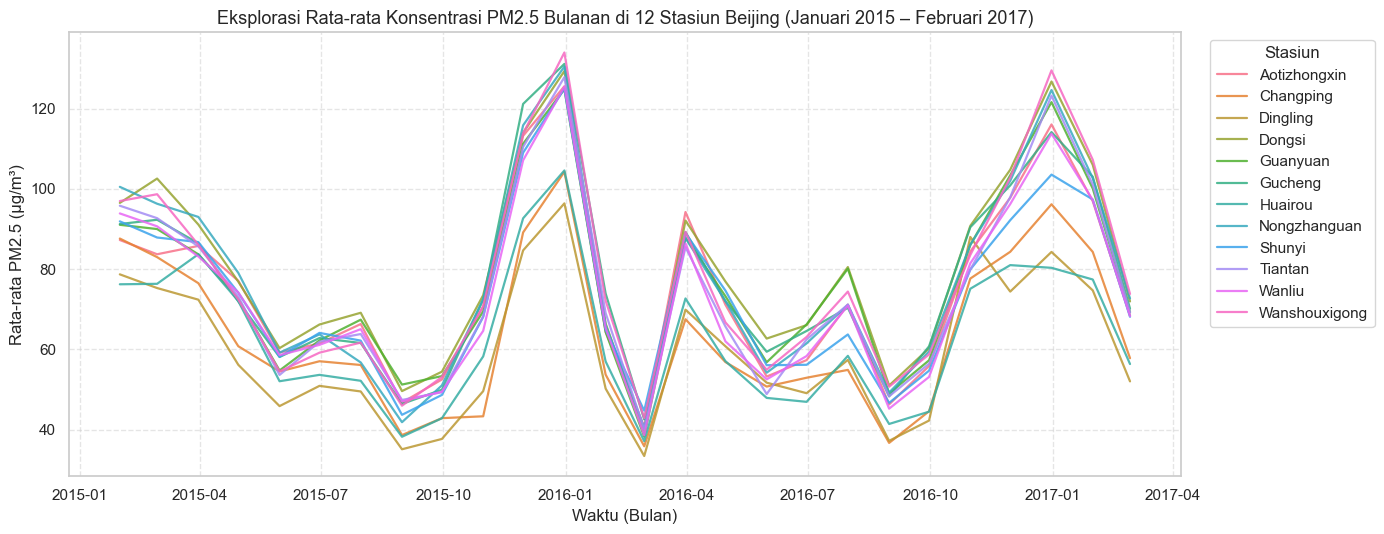

In [8]:
monthly_station_df = (
    df_filtered.groupby(['station', pd.Grouper(key='datetime', freq='ME')])['PM2.5']
    .mean()
    .reset_index()
)

plt.figure(figsize=(14, 5.5))
sns.lineplot(data=monthly_station_df, x='datetime', y='PM2.5', hue='station', linewidth=1.6, alpha=0.85)
plt.title('Eksplorasi Rata-rata Konsentrasi PM2.5 Bulanan di 12 Stasiun Beijing (Januari 2015 – Februari 2017)', fontsize=13)
plt.xlabel('Waktu (Bulan)')
plt.ylabel('Rata-rata PM2.5 (µg/m³)')
plt.legend(title='Stasiun', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Insight:**
- Grafik eksplorasi ke-12 stasiun sepanjang **Januari 2015 hingga Februari 2017** memperlihatkan bahwa seluruh stasiun bergerak serempak mengikuti gelombang musiman makro yang sama (memuncak serentak pada akhir tahun/musim dingin 2015–2016 dan 2016–2017, serta melandai pada pertengahan tahun), namun tetap mempertahankan celah (*gap*) konsentrasi yang konsisten antara stasiun pusat kota (*Urban*) di lapisan atas dan stasiun pinggiran (*Non-Urban*) di lapisan bawah.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Perbandingan Tingkat Polusi PM2.5 per Stasiun dan Kategori Wilayah (Periode 2015–2017)

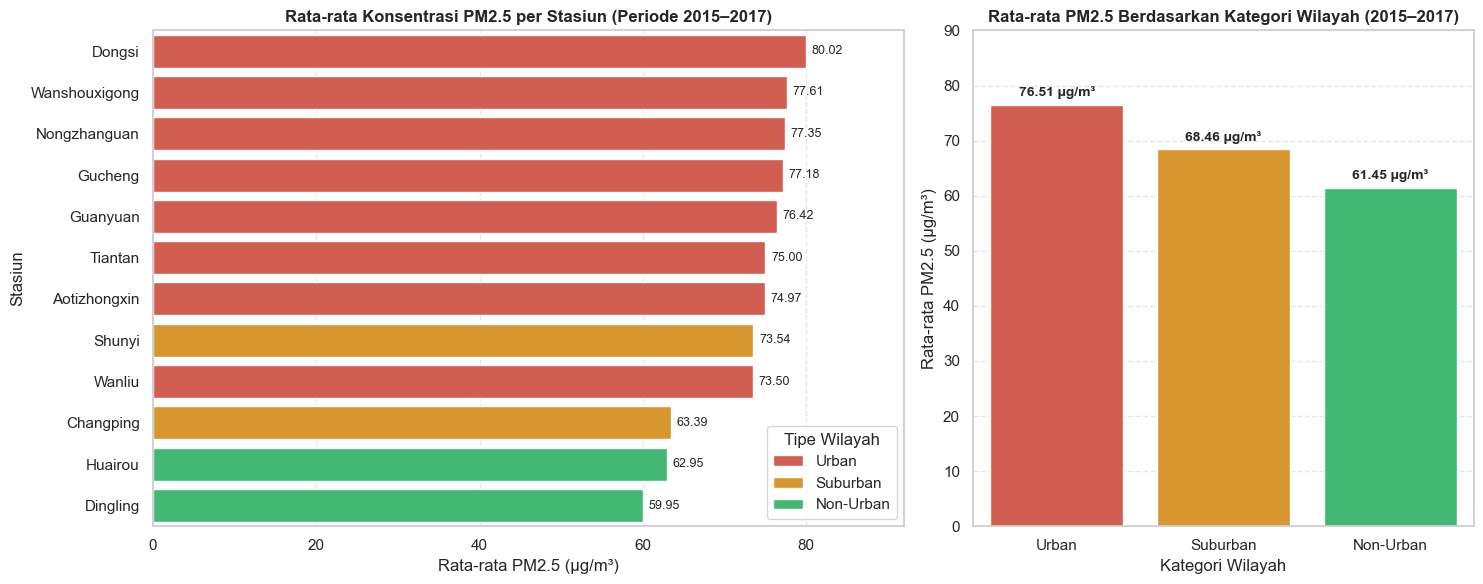

In [9]:
# Menggunakan df_filtered (Periode 2015-2017) agar selaras dengan cakupan Pertanyaan 1 dan EDA eda_q1
station_avg = (
    df_filtered.groupby(['station', 'station_type'])['PM2.5']
    .mean()
    .reset_index()
    .sort_values('PM2.5', ascending=False)
)
zone_avg = (
    df_filtered.groupby('station_type')['PM2.5']
    .mean()
    .reset_index()
    .sort_values('PM2.5', ascending=False)
)

palette_zone = {'Urban': '#e74c3c', 'Suburban': '#f39c12', 'Non-Urban': '#2ecc71'}

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [3, 2]})

# Subplot 1: Peringkat 12 Stasiun (2015-2017)
sns.barplot(
    data=station_avg, x='PM2.5', y='station', hue='station_type',
    palette=palette_zone, dodge=False, ax=axes[0]
)
axes[0].set_title('Rata-rata Konsentrasi PM2.5 per Stasiun (Periode 2015–2017)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Rata-rata PM2.5 (µg/m³)')
axes[0].set_ylabel('Stasiun')
axes[0].set_xlim(0, 92)
axes[0].legend(title='Tipe Wilayah', loc='lower right')
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.2f', padding=4, fontsize=9)

# Subplot 2: Rata-rata per Kategori Wilayah (2015-2017)
sns.barplot(
    data=zone_avg, x='station_type', y='PM2.5', hue='station_type',
    palette=palette_zone, legend=False, ax=axes[1]
)
axes[1].set_title('Rata-rata PM2.5 Berdasarkan Kategori Wilayah (2015–2017)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Kategori Wilayah')
axes[1].set_ylabel('Rata-rata PM2.5 (µg/m³)')
axes[1].set_ylim(0, 90)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.2f µg/m³', padding=4, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

**Insight:**
- **Hierarki Wilayah yang Tegas (2015–2017):** Secara agregat, wilayah **Urban** mencatatkan rata-rata konsentrasi PM2.5 tertinggi sebesar **76,51 µg/m³**, disusul **Suburban** sebesar **68,46 µg/m³**, dan **Non-Urban** sebesar **61,45 µg/m³** (selisih **15,06 µg/m³** atau sekitar **24,5% lebih tinggi** di kawasan Urban dibandingkan Non-Urban).
- **Stasiun Tertinggi & Terendah di Kategori Urban:** Dari 8 stasiun Urban, konsentrasi tertinggi tercatat di **Dongsi (80,02 µg/m³)**, diikuti **Wanshouxigong (77,61 µg/m³)**, **Nongzhanguan (77,35 µg/m³)**, dan **Gucheng (77,18 µg/m³)**. Sementara itu, stasiun Urban dengan rata-rata terendah adalah **Wanliu (73,50 µg/m³)** dan **Aotizhongxin (74,97 µg/m³)**.
- **Stasiun Tertinggi & Terendah di Kategori Suburban:** Di zona penyangga, **Shunyi** mencatatkan rata-rata tertinggi sebesar **73,54 µg/m³** (setara dengan batas bawah stasiun Urban karena kedekatannya dengan jalur logistik bandara dan kawasan industri), sedangkan **Changping** jauh lebih rendah sebesar **63,39 µg/m³**.
- **Stasiun Tertinggi & Terendah di Kategori Non-Urban:** Di zona luar kota, **Huairou** mencatatkan rata-rata **62,95 µg/m³**, sedangkan **Dingling** merupakan stasiun dengan kualitas udara paling bersih di seluruh Beijing dengan rata-rata **59,95 µg/m³**.

### Pertanyaan 2: Pola Jam Harian (Diurnal) dan Tren Fluktuasi Musiman PM2.5 (Periode 2015–2017)

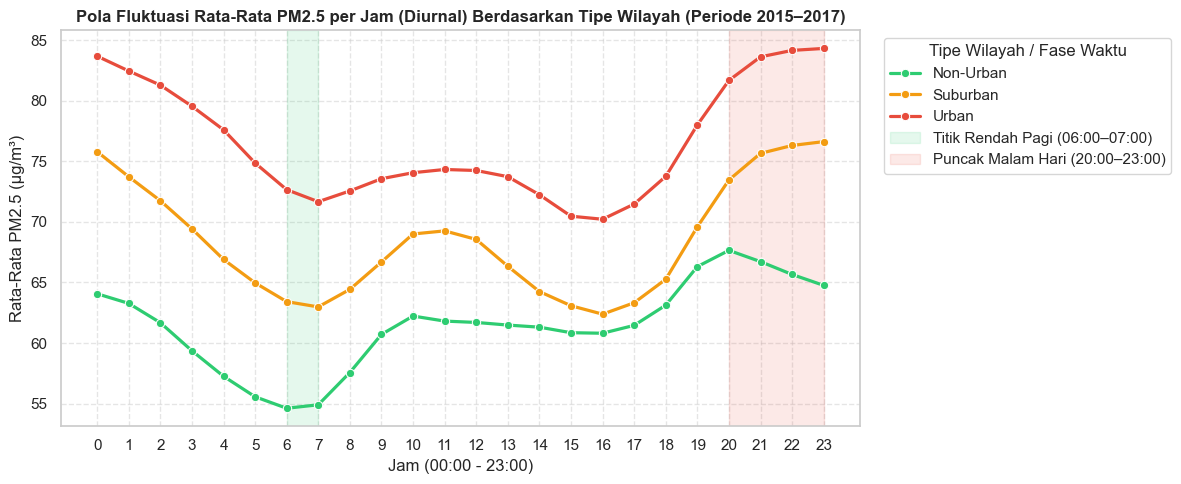

In [10]:
# 1. Visualisasi Pola Jam Harian (Diurnal) pada Periode 2015-2017 (menggunakan eda_q2 dari df_filtered)
palette_zone = {'Urban': '#e74c3c', 'Suburban': '#f39c12', 'Non-Urban': '#2ecc71'}

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=eda_q2, x='hour', y='PM2.5', hue='station_type',
    palette=palette_zone, marker='o', linewidth=2.3
)

# Highlight rentang lembah pagi (06:00-07:00) dan puncak malam (20:00-23:00)
plt.axvspan(6, 7, color='#2ecc71', alpha=0.12, label='Titik Rendah Pagi (06:00–07:00)')
plt.axvspan(20, 23, color='#e74c3c', alpha=0.12, label='Puncak Malam Hari (20:00–23:00)')

plt.title('Pola Fluktuasi Rata-Rata PM2.5 per Jam (Diurnal) Berdasarkan Tipe Wilayah (Periode 2015–2017)', fontsize=12, fontweight='bold')
plt.xlabel('Jam (00:00 - 23:00)')
plt.ylabel('Rata-Rata PM2.5 (µg/m³)')
plt.xticks(range(0, 24))
plt.legend(title='Tipe Wilayah / Fase Waktu', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

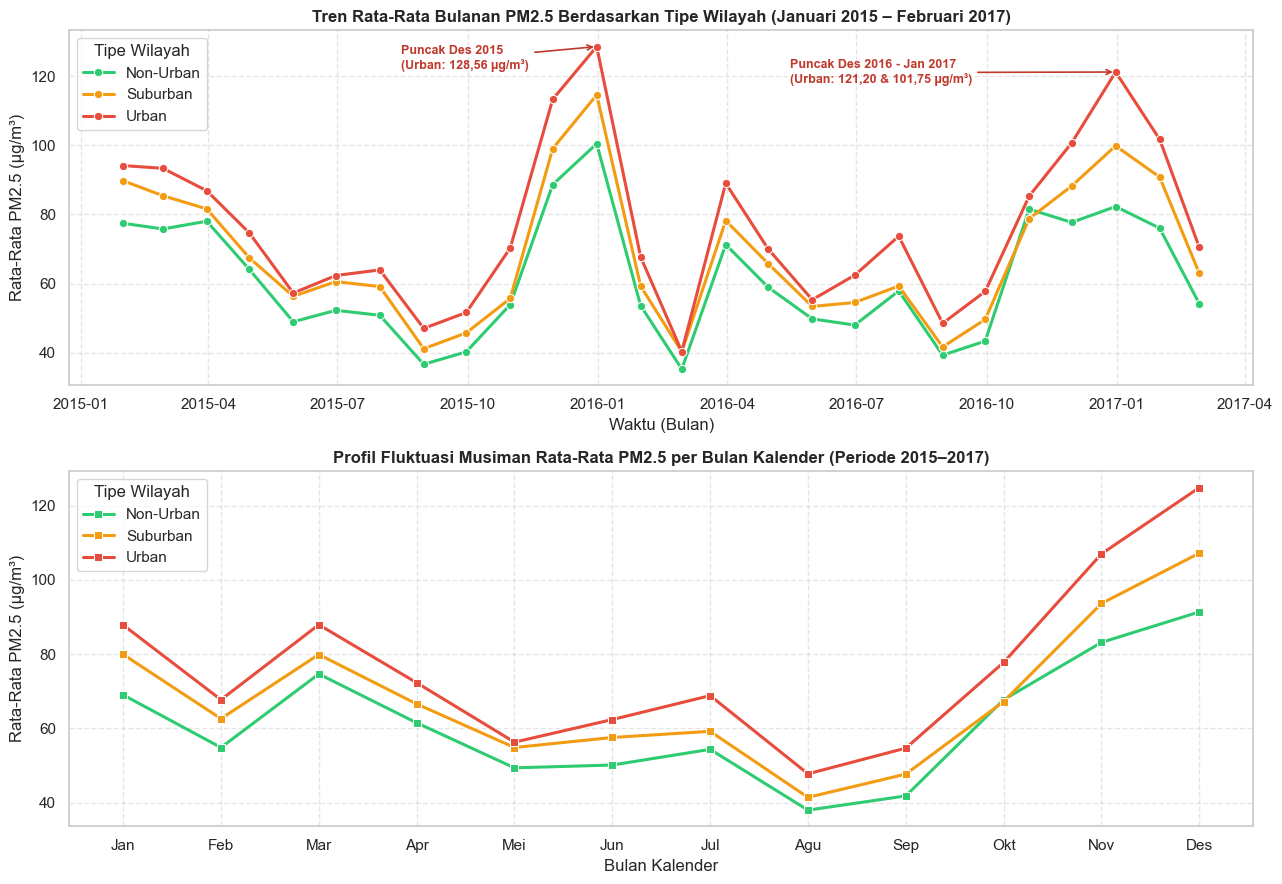

In [11]:
# 2. Visualisasi Resmi Tren Fluktuasi Musiman / Bulanan pada Rentang 2015–2017 (Januari 2015 - Februari 2017)
fig, axes = plt.subplots(2, 1, figsize=(13, 9))

# Panel Atas: Tren Deret Waktu Bulanan (Januari 2015 - Februari 2017)
sns.lineplot(
    data=eda_q2_monthly, x='datetime', y='PM2.5', hue='station_type',
    palette=palette_zone, marker='o', linewidth=2.2, ax=axes[0]
)
axes[0].set_title('Tren Rata-Rata Bulanan PM2.5 Berdasarkan Tipe Wilayah (Januari 2015 – Februari 2017)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Waktu (Bulan)')
axes[0].set_ylabel('Rata-Rata PM2.5 (µg/m³)')
axes[0].legend(title='Tipe Wilayah', loc='upper left')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Anotasi puncak musim dingin pada deret waktu 2015-2017
axes[0].annotate('Puncak Des 2015\n(Urban: 128,56 µg/m³)', xy=(pd.Timestamp('2015-12-31'), 128.56),
                 xytext=(pd.Timestamp('2015-08-15'), 122),
                 arrowprops=dict(arrowstyle='->', color='#c0392b', lw=1.2), fontsize=9, fontweight='bold', color='#c0392b')
axes[0].annotate('Puncak Des 2016 - Jan 2017\n(Urban: 121,20 & 101,75 µg/m³)', xy=(pd.Timestamp('2016-12-31'), 121.20),
                 xytext=(pd.Timestamp('2016-05-15'), 118),
                 arrowprops=dict(arrowstyle='->', color='#c0392b', lw=1.2), fontsize=9, fontweight='bold', color='#c0392b')

# Panel Bawah: Profil Siklus Musiman per Bulan Kalender (Januari - Desember, Rata-rata 2015-2017)
calendar_monthly_long = (
    df_filtered.groupby(['station_type', 'month'])['PM2.5']
    .mean()
    .reset_index()
)
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']

sns.lineplot(
    data=calendar_monthly_long, x='month', y='PM2.5', hue='station_type',
    palette=palette_zone, marker='s', linewidth=2.2, ax=axes[1]
)
axes[1].set_title('Profil Fluktuasi Musiman Rata-Rata PM2.5 per Bulan Kalender (Periode 2015–2017)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Bulan Kalender')
axes[1].set_ylabel('Rata-Rata PM2.5 (µg/m³)')
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(month_names)
axes[1].legend(title='Tipe Wilayah', loc='upper left')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Insight:**
- **Pola Jam Harian / Diurnal (2015–2017):**
  - **Puncak Malam Hari (20:00–23:00):** Konsentrasi polutan tertinggi di seluruh wilayah terjadi pada malam hari. Di wilayah **Urban**, puncak terjadi pada **pukul 23:00 (84,32 µg/m³)** dan **pukul 22:00 (84,15 µg/m³)**; di wilayah **Suburban**, puncak terjadi pada **pukul 23:00 (76,62 µg/m³)** dan **pukul 22:00 (76,31 µg/m³)**; sedangkan di wilayah **Non-Urban**, puncak tercapai sedikit lebih awal pada **pukul 20:00 (67,65 µg/m³)**. Lonjakan malam hari ini dipicu oleh menyusutnya lapisan batas atmosfer (*planetary boundary layer*) saat suhu permukaan mendingin serta beroperasinya armada truk logistik diesel berat yang diizinkan masuk kota pada malam hari.
  - **Lembah Pagi (06:00–07:00) dan Sore (15:00–16:00):** Di wilayah **Non-Urban**, konsentrasi terendah terjadi pada **pukul 06:00 (54,62 µg/m³)** dan **07:00 (54,90 µg/m³)** sebelum aktivitas harian meningkat. Sementara di **Urban** dan **Suburban**, selain lembah pagi pada **pukul 07:00** (**Urban 71,67 µg/m³**, **Suburban 62,98 µg/m³**), penurunan terdalam juga terjadi pada sore hari **pukul 16:00** (**Urban 70,22 µg/m³**, **Suburban 62,38 µg/m³**) ketika pemanasan matahari dan kecepatan angin siang/sore hari memaksimumkan dispersi vertikal polutan.
- **Pola Fluktuasi Musiman / Bulanan (2015–2017):**
  - **Lonjakan Ekstrem Musim Dingin (November–Januari):** Visualisasi deret waktu Januari 2015 – Februari 2017 menunjukkan siklus musiman berbentuk huruf U yang sangat tegas setiap tahunnya. Secara rata-rata kalender bulanan (2015–2017), polusi tertinggi terjadi pada **Desember (116,35 µg/m³)**, **November (100,81 µg/m³)**, **Maret (84,38 µg/m³)**, dan **Januari (83,39 µg/m³)**. Pada deret waktu bulanan, puncak tertinggi terjadi pada **Desember 2015** (**Urban 128,56 µg/m³**, **Suburban 114,59 µg/m³**, **Non-Urban 100,46 µg/m³**), diikuti musim dingin berikutnya pada **Desember 2016** (**Urban 121,20 µg/m³**) dan **Januari 2017** (**Urban 101,75 µg/m³**, **Suburban 90,80 µg/m³**, **Non-Urban 76,03 µg/m³**). Hal ini disebabkan oleh peningkatan pembakaran batu bara untuk pemanas ruangan (*central heating*) yang berpadu dengan fenomena inversi suhu musim dingin.
  - **Periode Udara Terbersih (Agustus–September):** Konsentrasi PM2.5 melandai ke titik terendah pada akhir musim panas, yaitu **Agustus (rata-rata gabungan 45,06 µg/m³: Urban 47,75 µg/m³, Suburban 41,40 µg/m³, Non-Urban 37,96 µg/m³)** dan **September (51,36 µg/m³)** berkat curah hujan musim panas (*wet deposition*) dan sirkulasi atmosfer yang aktif.

## Analisis Lanjutan: Clustering Risiko Kesehatan Udara & Pengaruh Faktor Meteorologi (Periode 2015–2017)

### Teknik Analisis Lanjutan: Clustering (Manual Grouping & Binning)
**Tujuan Analisis:**
Teknik analisis lanjutan yang digunakan pada proyek ini adalah **Clustering tanpa algoritma Machine Learning** melalui metode **Manual Grouping** dan **Binning** pada data periode analisis **2015–2017 (`df_filtered`)**:
1. **Manual Grouping:** Mengelompokkan ke-12 stasiun pemantauan ke dalam 3 zona tata ruang (*Urban*, *Suburban*, dan *Non-Urban*) berdasarkan karakteristik geografis dan aktivitas industri/transportasi lokal.
2. **Binning:** Membagi nilai numerik konsentrasi `PM2.5` ke dalam 5 kategori tingkat risiko kesehatan udara (*Good 0–35*, *Moderate 35–75*, *Unhealthy for Sensitive Groups 75–115*, *Unhealthy 115–150*, *Very Unhealthy >150 µg/m³*) untuk membandingkan proporsi waktu berudara sehat vs berbahaya di masing-masing zona wilayah.

pm25_category,Good (0-35),Moderate (35-75),Unhealthy for Sensitive (75-115),Unhealthy (115-150),Very Unhealthy (>150)
station_type,,,,,
Non-Urban,47.13,22.51,12.54,6.98,10.84
Suburban,42.59,23.33,13.82,7.40,12.86
Urban,38.04,23.47,15.16,7.94,15.39


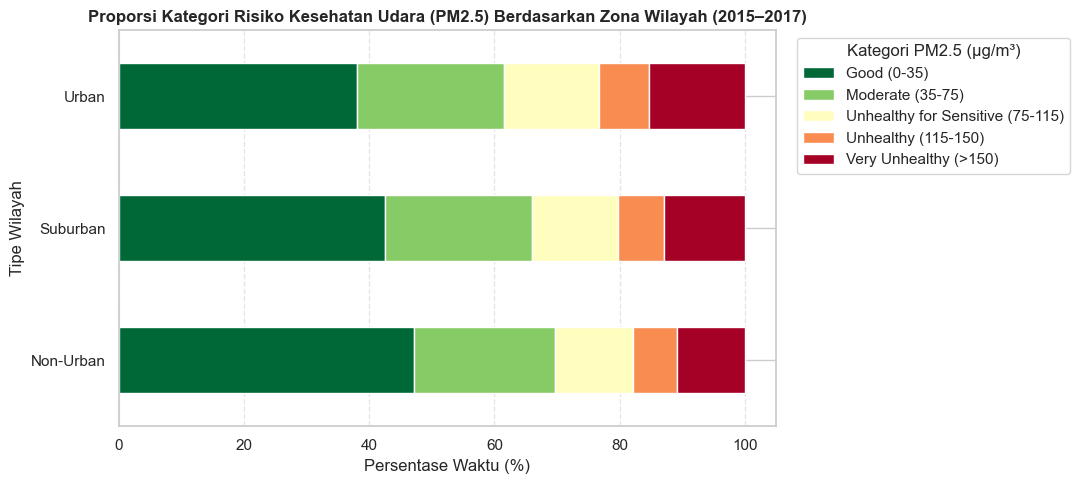

In [12]:
# Melakukan Binning pada konsentrasi PM2.5 berdasarkan ambang batas kesehatan udara (Periode 2015-2017)
bins = [0, 35, 75, 115, 150, np.inf]
labels = ['Good (0-35)', 'Moderate (35-75)', 'Unhealthy for Sensitive (75-115)', 'Unhealthy (115-150)', 'Very Unhealthy (>150)']

df['pm25_category'] = pd.cut(df['PM2.5'], bins=bins, labels=labels, include_lowest=True)
df_filtered['pm25_category'] = pd.cut(df_filtered['PM2.5'], bins=bins, labels=labels, include_lowest=True)

# Menghitung persentase kategori kualitas udara di tiap tipe wilayah (2015-2017)
category_dist = pd.crosstab(df_filtered['station_type'], df_filtered['pm25_category'], normalize='index') * 100
display(category_dist.round(2))

# Visualisasi Stacked Bar Chart
ax = category_dist.plot(kind='barh', stacked=True, figsize=(11, 5), colormap='RdYlGn_r')
plt.title('Proporsi Kategori Risiko Kesehatan Udara (PM2.5) Berdasarkan Zona Wilayah (2015–2017)', fontsize=12, fontweight='bold')
plt.xlabel('Persentase Waktu (%)')
plt.ylabel('Tipe Wilayah')
plt.legend(title='Kategori PM2.5 (µg/m³)', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

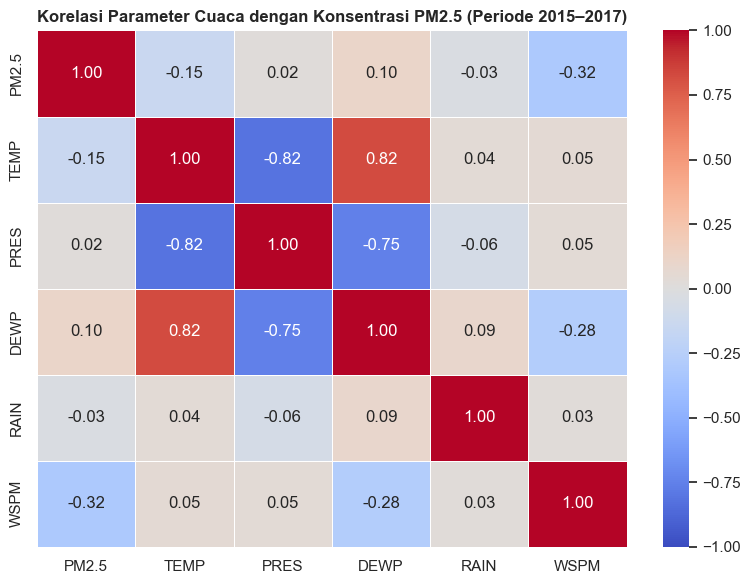

In [13]:
# Korelasi antara polutan PM2.5 dan parameter cuaca (Periode 2015-2017)
weather_cols = ['PM2.5', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
corr_matrix = df_filtered[weather_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Korelasi Parameter Cuaca dengan Konsentrasi PM2.5 (Periode 2015–2017)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Insight:**
- **Distribusi Kategori Risiko Kesehatan (Binning 2015–2017):** Wilayah **Non-Urban** menikmati proporsi waktu udara sehat (*Good 0–35 µg/m³*) tertinggi sebesar **47,13%** dan proporsi kategori *Very Unhealthy (>150 µg/m³)* paling rendah (**10,84%**). Sebaliknya, wilayah **Urban** hanya merasakan udara kategori *Good* selama **38,04%** waktu, sementara jam dengan kualitas udara berbahaya (*Unhealthy 115–150* ditambah *Very Unhealthy >150 µg/m³*) mencapai **23,71%** (hampir seperempat waktu sepanjang 2015–2017).
- **Peran Kecepatan Angin (`WSPM`, r = -0,32):** Kecepatan angin memiliki korelasi negatif terkuat terhadap `PM2.5`. Hembusan angin kencang efektif menyapu dan mendispersi partikel polutan dari permukaan kota.
- **Kondisi Suhu Dingin (`TEMP`, r = -0,15) & Kelembapan/Titik Embun (`DEWP`, r = +0,10):** Korelasi negatif antara suhu udara dan `PM2.5` mengonfirmasi temuan musiman bahwa penurunan suhu pada musim dingin berasosiasi dengan peningkatan konsentrasi partikel polutan akibat inversi termal dan emisi pemanas ruangan.

## Conclusion & Recommendation

- **Conclusion Pertanyaan 1 (Perbandingan Stasiun & Kategori Wilayah Periode 2015–2017):**
  Berdasarkan hasil analisis data periode **2015–2017**, tingkat polusi `PM2.5` menunjukkan stratifikasi tata ruang yang sangat jelas: kategori wilayah **Urban** mencatatkan rata-rata konsentrasi tertinggi sebesar **76,51 µg/m³**, diikuti kategori **Suburban** sebesar **68,46 µg/m³**, dan kategori **Non-Urban** sebesar **61,45 µg/m³**. Di masing-masing kategori wilayah, stasiun dengan rata-rata konsentrasi `PM2.5` tertinggi dan terendah adalah:
  1. **Wilayah Urban:** Tertinggi di stasiun **Dongsi (80,02 µg/m³)** — disusul **Wanshouxigong (77,61 µg/m³)**, **Nongzhanguan (77,35 µg/m³)**, dan **Gucheng (77,18 µg/m³)** — sedangkan terendah berada di stasiun **Wanliu (73,50 µg/m³)** dan **Aotizhongxin (74,97 µg/m³)**.
  2. **Wilayah Suburban:** Tertinggi di stasiun **Shunyi (73,54 µg/m³)** dan terendah di stasiun **Changping (63,39 µg/m³)**.
  3. **Wilayah Non-Urban:** Tertinggi di stasiun **Huairou (62,95 µg/m³)** dan terendah di stasiun **Dingling (59,95 µg/m³)** yang sekaligus menjadi stasiun dengan kualitas udara paling bersih di seluruh Beijing.

- **Conclusion Pertanyaan 2 (Pola Jam Harian / Diurnal & Fluktuasi Musiman Periode 2015–2017):**
  1. **Pola Jam Harian (Diurnal):** Sepanjang periode **2015–2017**, puncak rata-rata konsentrasi `PM2.5` harian terjadi pada **malam hari (pukul 20:00–23:00)** di seluruh wilayah, yaitu mencapai titik tertinggi pada **pukul 23:00 di wilayah Urban (84,32 µg/m³)** dan **Suburban (76,62 µg/m³)**, serta pada **pukul 20:00 di wilayah Non-Urban (67,65 µg/m³)**. Sebaliknya, konsentrasi terendah terjadi pada **pagi hari (pukul 06:00–07:00)** — yakni **Non-Urban 54,62 µg/m³** (pukul 06:00), **Suburban 62,98 µg/m³** (pukul 07:00), dan **Urban 71,67 µg/m³** (pukul 07:00) — serta pada **sore hari (pukul 15:00–16:00)** saat dispersi atmosfer maksimum (**Urban 70,22 µg/m³** dan **Suburban 62,38 µg/m³** pada pukul 16:00).
  2. **Pola Fluktuasi Musiman (2015–2017):** Tren bulanan sepanjang **Januari 2015 hingga Februari 2017** membuktikan adanya lonjakan polusi berulang setiap **musim dingin (November–Januari)** dengan rata-rata kalender bulanan tertinggi pada **Desember (116,35 µg/m³)**, **November (100,81 µg/m³)**, **Maret (84,38 µg/m³)**, dan **Januari (83,39 µg/m³)**. Puncak bulanan tertinggi tercatat pada **Desember 2015** (**Urban 128,56 µg/m³**, **Suburban 114,59 µg/m³**, **Non-Urban 100,46 µg/m³**), **Desember 2016** (**Urban 121,20 µg/m³**), serta **Januari 2017** (**Urban 101,75 µg/m³**, **Suburban 90,80 µg/m³**, **Non-Urban 76,03 µg/m³**). Sebaliknya, konsentrasi terendah selalu terjadi pada akhir musim panas yaitu **Agustus (rata-rata 45,06 µg/m³)** dan **September (51,36 µg/m³)**.

**Rekomendasi Action Item:**
- **Pemberlakuan Peringatan Kualitas Udara Musiman (November–Januari):** Mengaktifkan protokol peringatan dini kesehatan masyarakat (penggunaan masker respirator N95, penyaringan udara dalam ruangan, dan pembatasan aktivitas luar ruangan di sekolah/area publik) secara terjadwal setiap memasuki bulan **November hingga Januari**, khususnya di zona *Urban* dan *Suburban* yang rata-rata bulanannya menembus `>100 µg/m³`.
- **Regulasi Ketat & Penjadwalan Ulang Emisi Truk Malam Hari (19:00–00:00):** Memperketat standar emisi gas buang (wajib standar Euro V/VI atau kendaraan listrik logistik) serta membatasi kuota armada truk diesel berat yang masuk ke koridor perkotaan pada jam kritis **20:00–23:00**, mengingat jam tersebut bertepatan dengan penyusutan lapisan batas atmosfer yang memerangkap polutan hingga rata-rata `84,32 µg/m³` di zona *Urban*.
- **Zonasi Emisi Rendah (*Low Emission Zones*) Berbasis Prioritas Stasiun:** Menetapkan kawasan di sekitar stasiun terpolusi tertinggi pada masing-masing zona — terutama **Dongsi (`80,02 µg/m³`)**, **Wanshouxigong (`77,61 µg/m³`)**, **Nongzhanguan (`77,35 µg/m³`)**, dan **Gucheng (`77,18 µg/m³`)** di zona *Urban* serta **Shunyi (`73,54 µg/m³`)** di zona *Suburban* — sebagai lokasi prioritas penerapan *Low Emission Zone*, percepatan elektrifikasi transportasi publik, dan pemasangan menara pemurni udara (*smog-free towers*).

In [14]:
# Ekspor data bersih periode analisis (2015-2017) untuk Streamlit Dashboard
# Karena seluruh Pertanyaan Bisnis (Pertanyaan 1 & Pertanyaan 2 baik diurnal maupun musiman)
# berada pada cakupan waktu 2015-2017, main_data.csv kini 100% mereplikasi hasil analisis di notebook.
cols_to_keep = [
    'datetime', 'year', 'month', 'hour', 'station', 'station_type',
    'PM2.5', 'PM10', 'SO2', 'NO2', 'TEMP', 'PRES', 'WSPM', 'pm25_category'
]
dashboard_df = df_filtered[cols_to_keep].round(2)

os.makedirs('dashboard', exist_ok=True)
dashboard_df.to_csv('dashboard/main_data.csv', index=False)
print(f"Berhasil mengekspor dashboard/main_data.csv dengan {len(dashboard_df):,} baris!")

Berhasil mengekspor dashboard/main_data.csv dengan 227,520 baris!
